# 02 – Préparation : cible RUL, découpage par moteur, normalisation

Objectif : construire des jeux de données propres et **sans fuite d'information** pour les modèles.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.data.load import load_cmapss, add_rul, add_rul_test, PROJECT_ROOT
from src.data.split import split_units, apply_split
from src.features.preprocess import SensorScaler, FEATURES_FD001, DROP_COLS_FD001

sns.set_theme(style="whitegrid")
RUL_CLIP = 125

## 1. Cible RUL plafonnée

Les capteurs sont plats en début de vie puis la dégradation s'accélère (notebook 01). On plafonne donc la RUL à 125 : le modèle n'a pas à distinguer RUL = 300 et RUL = 200, ce qui est impossible avec des capteurs encore stables.

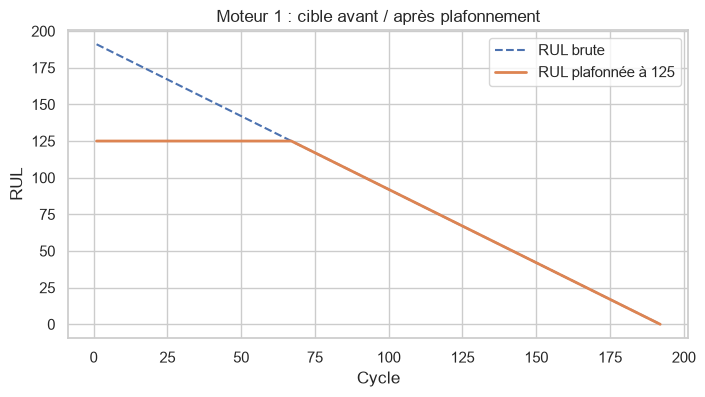

In [2]:
train, test, rul_test = load_cmapss("FD001")
train = add_rul(train, clip=RUL_CLIP)
test = add_rul_test(test, rul_test, clip=RUL_CLIP)

raw = add_rul(train[train.unit == 1], clip=None)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(raw.cycle, raw.RUL, "--", label="RUL brute")
ax.plot(raw.cycle, train[train.unit == 1].RUL, lw=2, label=f"RUL plafonnée à {RUL_CLIP}")
ax.set(xlabel="Cycle", ylabel="RUL", title="Moteur 1 : cible avant / après plafonnement")
ax.legend()
plt.show()

## 2. Découpage par moteur

Règle d'or : un moteur appartient à **un seul** ensemble. Sinon le modèle verrait des cycles voisins du même moteur à l'entraînement et à l'évaluation, et les scores seraient trop optimistes.

In [3]:
groups = split_units(train, fracs=(0.70, 0.15, 0.15), seed=42)
for k, u in groups.items():
    print(f"{k:<6}: {len(u):>3} moteurs -> {[int(x) for x in u[:8]]}...")

sets = apply_split(train, groups)
sets["test"] = test

# Vérification : aucun moteur commun
assert not set(groups["train"]) & set(groups["calib"])
assert not set(groups["train"]) & set(groups["val"])
assert not set(groups["calib"]) & set(groups["val"])
print("\nAucun moteur partagé entre les ensembles ✔")

train :  70 moteurs -> [1, 2, 3, 4, 5, 6, 8, 10]...
calib :  15 moteurs -> [7, 12, 31, 35, 45, 50, 55, 59]...
val   :  15 moteurs -> [9, 13, 14, 15, 20, 23, 36, 37]...

Aucun moteur partagé entre les ensembles ✔


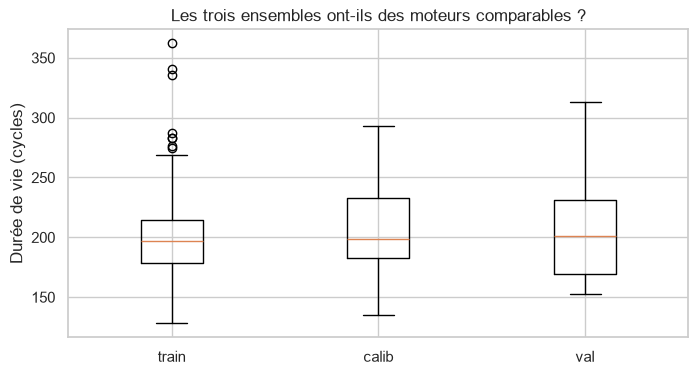

In [4]:
lifetimes = {k: v.groupby("unit").cycle.max() for k, v in sets.items() if k != "test"}
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(list(lifetimes.values()))
ax.set_xticks(range(1, len(lifetimes) + 1), list(lifetimes.keys()))
ax.set(ylabel="Durée de vie (cycles)", title="Les trois ensembles ont-ils des moteurs comparables ?")
plt.show()

## 3. Sélection des capteurs et normalisation

- Supprimés : op1, op2, op3, s1, s5, s6, s10, s16, s18, s19
- Gardés : 14 capteurs
- Normalisation ajustée **sur le train uniquement**, puis appliquée aux autres ensembles.

In [5]:
scaler = SensorScaler(FEATURES_FD001).fit(sets["train"])
processed = {k: scaler.transform(v)[["unit", "cycle"] + FEATURES_FD001 + ["RUL"]] for k, v in sets.items()}

print("Moyennes après normalisation (train ≈ 0, autres proches de 0) :")
pd.DataFrame({k: v[FEATURES_FD001].mean() for k, v in processed.items()}).round(2)

Moyennes après normalisation (train ≈ 0, autres proches de 0) :


,train,calib,val,test
s2,-0.0,-0.06,-0.03,-0.43
s3,0.0,-0.07,-0.01,-0.41
s4,0.0,-0.06,-0.05,-0.49
s7,-0.0,0.07,0.05,0.46
s8,0.0,-0.04,-0.11,-0.39
s9,-0.0,-0.12,0.11,-0.30
s11,0.0,-0.07,-0.05,-0.49
s12,-0.0,0.05,0.06,0.47
s13,-0.0,-0.02,-0.11,-0.37
s14,0.0,-0.13,0.13,-0.25


## 4. Sauvegarde

In [6]:
out_dir = PROJECT_ROOT / "data" / "processed"
out_dir.mkdir(parents=True, exist_ok=True)
for k, v in processed.items():
    v.to_csv(out_dir / f"FD001_{k}.csv", index=False)
    print(f"{k:<6}: {v.shape} -> FD001_{k}.csv")

train : (14407, 17) -> FD001_train.csv
calib : (3160, 17) -> FD001_calib.csv
val   : (3064, 17) -> FD001_val.csv
test  : (13096, 17) -> FD001_test.csv


## 5. Conclusions

**En résumé :** la RUL est plafonnée à 125 et les moteurs sont répartis sans recouvrement en train (70), calibration (15) et validation (15), avec une normalisation ajustée sur le train seul. Aucune fuite d'information n'est possible.

- **Cible** : RUL plafonnée à 125 (RUL « piecewise linear »), car les capteurs ne distinguent pas un moteur à 300 cycles de la panne d'un moteur à 200.
- **Découpage par moteur** (jamais par ligne, pour éviter les fuites) : 70 moteurs train (14 407 lignes), 15 calibration (3 160), 15 validation (3 064). Aucun moteur partagé. Les durées de vie médianes sont comparables (~200 cycles) dans les trois ensembles.
- **Normalisation** ajustée sur le train uniquement. Moyennes après normalisation : 0 sur le train, ±0,1 sur calib et val (découpage sain), ±0,45 sur le test.
- **Écart du test** : normal, ses trajectoires sont coupées avant la panne donc ses moteurs sont en moyenne plus jeunes. Conséquence pour la conformal prediction : il faudra calibrer sur des trajectoires coupées comme le test.